```
ConstantInterpolation(u,t) - A piecewise constant interpolation.

LinearInterpolation(u,t) - A linear interpolation.

QuadraticInterpolation(u,t) - A quadratic interpolation.

LagrangeInterpolation(u,t,n) - A Lagrange interpolation of order n.

QuadraticSpline(u,t) - A quadratic spline interpolation.

CubicSpline(u,t) - A cubic spline interpolation.

AkimaInterpolation(u, t) - Akima spline interpolation provides a smoothing effect and is computationally efficient.

BSplineInterpolation(u,t,d,pVec,knotVec) - An interpolation B-spline. This is a B-spline which hits each of the data points. The argument choices are:

d - degree of B-spline
pVec - Symbol to Parameters Vector, pVec = :Uniform for uniform spaced parameters and pVec = :ArcLen for parameters generated by chord length method.
knotVec - Symbol to Knot Vector, knotVec = :Uniform for uniform knot vector, knotVec = :Average for average spaced knot vector.
BSplineApprox(u,t,d,h,pVec,knotVec) - A regression B-spline which smooths the fitting curve. The argument choices are the same as the BSplineInterpolation, with the additional parameter h<length(t) which is the number of control points to use, with smaller h indicating more smoothing.

CubicHermiteSpline(du, u, t) - A third order Hermite interpolation, which matches the values and first (du) order derivatives in the data points exactly.

PCHIPInterpolation(u, t) - a type of CubicHermiteSpline where the derivative values du are derived from the input data in such a way that the interpolation never overshoots the data.

QuinticHermiteSpline(ddu, du, u, t) - A fifth order Hermite interpolation, which matches the values and first (du) and second (ddu) order derivatives in the data points exactly.
```

CubicHermiteSpline with 10 points
┌──────┬───────────┐
│    t │         u │
├──────┼───────────┤
│  1.0 │  0.540402 │
│  2.0 │ 0.0772338 │
│  3.0 │  0.330891 │
│  4.0 │ 0.0788564 │
│  5.0 │  0.766783 │
│  6.0 │ 0.0338798 │
│  7.0 │  0.740326 │
│  8.0 │  0.370456 │
│  9.0 │  0.230273 │
│ 10.0 │  0.906372 │
└──────┴───────────┘


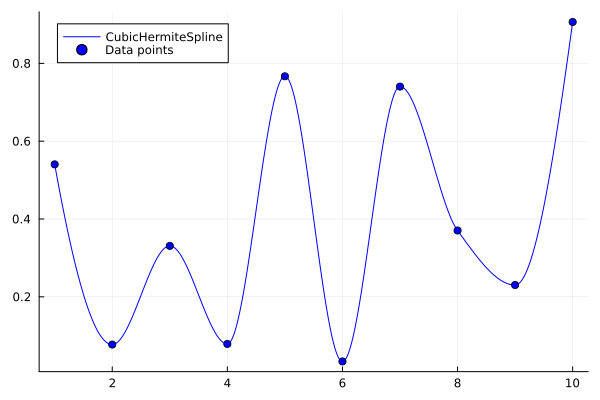

In [1]:
# using DataInterpolations: PCHIPInterpolation
using DataInterpolations
using Plots

u = rand(10)
t = 1:10

pchip = PCHIPInterpolation(u, t)
display(pchip)
plot(pchip)

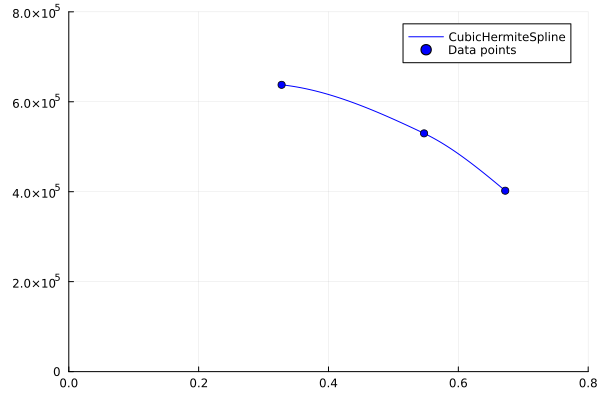

In [2]:
"""
    // 样本 A 档三点: (1180 m3/h, 65 m) (1970, 54) (2420, 41)
    // dp = H * 9810 Pa
    pressure(
      V_flow = {0.32778, 0.54722, 0.67222},
      dp     = {637650,  529740,  402210}),
    // 样本轴功率 261.1 / 329.1 / 342.0 kW, 除以电机效率 0.955 得输入电功率
    power(
      V_flow = {0.32778, 0.54722, 0.67222},
      P      = {273400,  344600,  358100}));
"""

dps = [637650,  529740,  402210]
V_flows = [0.32778, 0.54722, 0.67222]

dPcurve = PCHIPInterpolation(dps, V_flows)

plot(dPcurve; xlims = (0, 0.8), ylims = (0, 8e5))

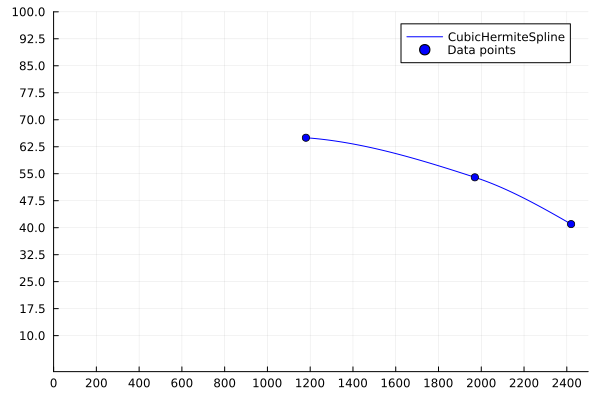

In [3]:
V_flows = [1180, 1970, 2420]
Hs = [65, 54, 41]
dPcurve_head = PCHIPInterpolation(Hs, V_flows)
display(plot(dPcurve_head; 
            xlims = (0, 2500), 
            ylims = (0, 100), 
            grid = true,
            xticks = 0:200:2500,
            yticks = 10:7.5:100))

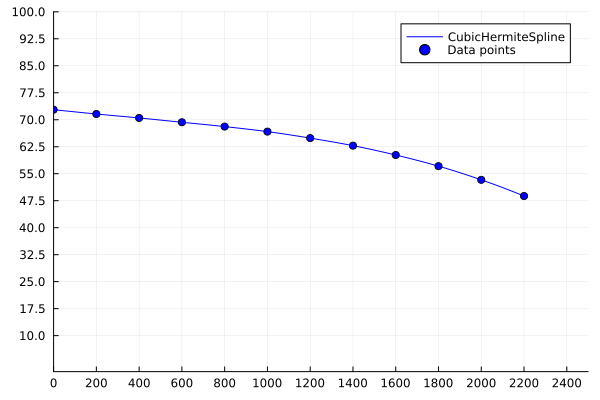

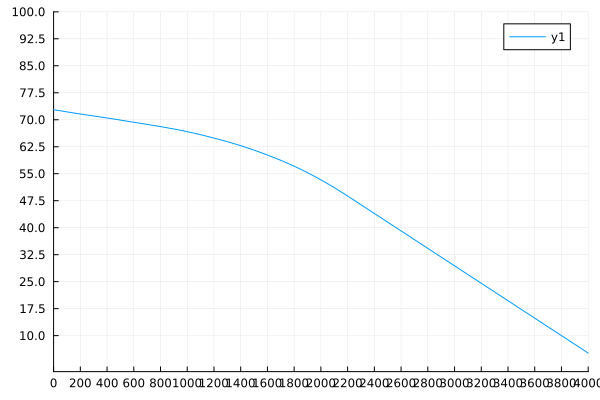

In [13]:
"""  V_flow = {0,       0.05556, 0.11111, 0.16667, 0.22222, 0.27778,
            0.32778, 0.38889, 0.44444, 0.50000, 0.54722, 0.67222},
  dp     = {704358,  695529,  686700,  675909,  664137,  649422,
            637650,  614106,  592524,  565056,  529740,  402210}),"""

"""dps = [704358,  695529,  686700,  675909,  664137,  649422,
            637650,  614106,  592524,  565056,  529740,  402210]
V_flows = [0,       0.05556, 0.11111, 0.16667, 0.22222, 0.27778,
            0.32778, 0.38889, 0.44444, 0.50000, 0.54722, 0.67222]"""

"""V_flows = [0,      200,   400,   600,   800,   1000,
           1180,   1400,  1600,  1800,  1970,  2420]      # m3/h
Hs      = [71.8,   70.9,  70.0,  68.9,  67.7,  66.2,
           65.0,   62.6,  60.4,  57.6,  54.0,  41.0]      # m"""

V_flows = [0, 		200, 	400, 	600, 	800, 	1000, 	
			1200, 	1400, 	1600, 	1800, 	2000, 2200]
Hs      = [72.8, 	71.6, 	70.5,	69.3, 	68.1, 	66.7, 
			64.9, 	62.8, 	60.2, 	57.1, 	53.3, 	48.8]

# dPcurve = PCHIPInterpolation(dps, V_flows)
# display(plot(dPcurve; xlims = (0, 0.8), ylims = (0, 8e5)))

# dPcurve_head = PCHIPInterpolation(Hs, V_flows, extrapolation = ExtrapolationType.Extension)
dPcurve_head = PCHIPInterpolation(Hs, V_flows, extrapolation = ExtrapolationType.Linear)
display(plot(dPcurve_head; 
            xlims = (0, 2500), 
            ylims = (0, 100), 
            grid = true,
            xticks = 0:200:2500,
            yticks = 10:7.5:100))

xs = 0:100:4000
ys = dPcurve_head(xs)
display(plot(xs, ys; 
            xlims = (0, 4000), 
            ylims = (0, 100), 
            grid = true,
            xticks = 0:200:4000,
            yticks = 10:7.5:100))

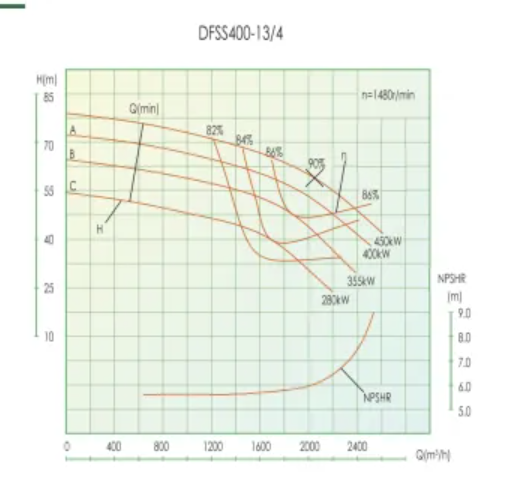

In [5]:
dPcurve_head(-1)

72.80625119538043